**Table of contents**<a id='toc0_'></a>    
- [1. Introduction](#toc1_)    
- [2. Preparing bike-sharing data](#toc2_)    
  - [2.1 Selecting top 3 German cities](#toc2_1_)    
  - [2.2 Converting individual trips into hourly counts](#toc2_2_)    
- [3. Adding weather records to hourly counts](#toc3_)    
- [4. Preparing the final data frame for modelling](#toc4_)    
  - [4.1 Adding holidays and weekends](#toc4_1_)    
  - [4.2 Fixing duplicates on 2 AM on Oct 30 (end of Daylight Savings Time)](#toc4_2_)    
  - [4.3 Adding school and university breaks](#toc4_3_)    
  - [4.4 Examining the dataset](#toc4_4_)    
    - [4.4.1 Profile report](#toc4_4_1_)    
    - [4.4.2 Days with <24 hours of data](#toc4_4_2_)    
    - [4.4.3 Creating column weather_group](#toc4_4_3_)    
    - [4.4.4 Filling NA's in rain_1h and snow_1h](#toc4_4_4_)    
    - [4.4.5 Final examination](#toc4_4_5_)    
- [5. Extra - Effect of strikes (not included in modelling)](#toc5_)    

<!-- vscode-jupyter-toc-config
	numbering=false
	anchor=true
	flat=false
	minLevel=1
	maxLevel=6
	/vscode-jupyter-toc-config -->
<!-- THIS CELL WILL BE REPLACED ON TOC UPDATE. DO NOT WRITE YOUR TEXT IN THIS CELL -->

# <a id='toc1_'></a>[1. Introduction](#toc0_)

In this file, we show how we arrived at the final dataset that we used for our machine learning models and for the data visualizations in our app.

Our data came from two main sources:
- Bike-sharing data are from a publicly available **[European Bike-Sharing Dataset](https://github.com/tumftm/european-bike-sharing-dataset)**.
- Weather data are from historical weather records by **[OpenWeather](https://openweathermap.org/api/history-bulk?collection=historical)**.

(1) From the European Bike-Sharing Dataset, we took 2 csv files:     
- **trips.csv** - with the information about individual bike trips       
- **cities.csv** with the information about the cities where the trips took place 

The path to *trips.csv* and *cities.csv* is the following:            
Repository > full > dataset.zip > trips.csv, cities.csv

(2) From OpenWeather, we purchased weather records for 2022-2023 for three cities - Berlin, Cologne, and Dresden.              
We cannot share these records publicly due to the company's policy.

Unfortunately, since one of our sources includes commercial data that cannot be redistributed, we cannot share our dataset publicly on GitHub.       

# <a id='toc2_'></a>[2. Preparing bike-sharing data](#toc0_)

The goal of this step is:
- to select top 3 German cities with the most bike-sharing trips 
- to convert the information about individual bike trips into hourly bike trip counts

## <a id='toc2_1_'></a>[2.1 Selecting top 3 German cities](#toc0_)

In [177]:
#Loading the necessary packages:
import pandas as pd
import numpy as np

from pytz import timezone
from datetime import date, timedelta, datetime

import holidays

import gc

import matplotlib.pyplot as plt

from data_profiling import ProfileReport


In [178]:
#Making sure a later plot shows correctly:
%matplotlib inline

In [179]:
#Importing the data frames from the csv files trips.csv and cities.csv:
trips = pd.read_csv("../data/bikesharing/trips.csv")
cities = pd.read_csv("../data/bikesharing/cities.csv")

Here we can see that the data frame "trips" includes individual bike-sharing trips, 1 row = 1 trip:

In [180]:
trips.sample(10)

,bike_id,city_id,time_start,lon_start,lat_start,lon_end,lat_end,station_id_start,station_id_end,battery_start,battery_end,duration,distance
20089088,609048,497,1.687703e+09,19.134910,50.273730,19.175876,50.268659,6753170.0,27603062.0,NaN,NaN,960.0,2965.588024
12535145,240085,701,1.666874e+09,-5.563197,42.612785,-5.570671,42.597232,48876114.0,48875631.0,NaN,NaN,780.0,1834.410243
1084248,19495,362,1.679742e+09,13.385606,52.510027,13.398167,52.507236,NaN,3173656.0,NaN,NaN,420.0,904.980502
20773530,611672,812,1.687637e+09,21.031269,52.239205,21.040962,52.292359,4393742.0,2585932.0,NaN,NaN,3660.0,5947.157003
12402206,224422,14,1.679011e+09,6.938753,50.930649,6.931060,50.925089,NaN,NaN,NaN,NaN,240.0,820.324930
22433642,710501,658,1.673895e+09,12.000622,57.681076,11.984083,57.685286,31054622.0,30922176.0,NaN,NaN,840.0,1088.921576
21032276,612270,812,1.685725e+09,21.018331,52.132479,21.056819,52.140391,172295073.0,2585905.0,NaN,NaN,1440.0,2770.207585
22401085,710257,658,1.677083e+09,11.934371,57.698718,11.987962,57.700117,32945034.0,31105279.0,NaN,NaN,7320.0,3188.084009
19667734,602867,148,1.677680e+09,17.020981,51.111489,17.044998,51.128876,12499401.0,12914435.0,NaN,NaN,1140.0,2558.863177
20952704,611924,812,1.687624e+09,21.031009,52.288592,21.037949,52.269041,2585937.0,2585961.0,NaN,NaN,900.0,2224.653007


The data frame with trips is very big (over 25 million rows), so we would need to limit our scope:

In [181]:
trips.shape

(25210627, 13)

Let's select top 3 German cities, with the most bike trips:

In [182]:
# Get IDs of German cities
german_city_ids = cities.loc[cities["country"] == "DE", "id"]

# Filter trips to the ones in German cities
german_trips = trips[trips["city_id"].isin(german_city_ids)]

# Count trips per city and select top 3
top_cities = (
    german_trips
    .groupby("city_id")
    .size()
    .reset_index(name="n_observations")
    .sort_values(["n_observations", "city_id"], ascending=[False, True])
    .head(3)
)

display(top_cities)

,city_id,n_observations
3,14,2154977
69,685,1403079
31,362,1213498


In [183]:
# Select trips from the top 3 German cities
top3_ger_cities_trips = trips[
    trips["city_id"].isin(top_cities["city_id"])
].copy()

top3_ger_cities_trips.sample(3)

,bike_id,city_id,time_start,lon_start,lat_start,lon_end,lat_end,station_id_start,station_id_end,battery_start,battery_end,duration,distance
10577906,220527,14,1.686594e+09,6.976217,50.932480,6.981556,50.931231,NaN,NaN,NaN,NaN,300.0,399.101712
24251991,930392,685,1.663260e+09,13.738849,51.070924,13.747187,51.067449,NaN,NaN,NaN,NaN,300.0,699.092660
11638113,223121,14,1.667373e+09,6.938717,50.926587,6.923708,50.916907,NaN,NaN,NaN,NaN,480.0,1505.124411


In [184]:
# Add city names to the trips from the top 3 German cities:
top3_ger_cities_trips = top3_ger_cities_trips.merge(
    cities[["id", "name"]],
    left_on="city_id",
    right_on="id",
    how="left"
)

top3_ger_cities_trips = top3_ger_cities_trips.rename(
    columns={"name": "city_name"}
)

top3_ger_cities_trips = top3_ger_cities_trips.drop(columns="id")

top3_ger_cities_trips.sample(7)

,bike_id,city_id,time_start,lon_start,lat_start,lon_end,lat_end,station_id_start,station_id_end,battery_start,battery_end,duration,distance,city_name
445548,16530,362,1.670192e+09,13.462885,52.515203,13.449485,52.516491,9449369.0,20550322.0,NaN,NaN,480.0,917.977192,Berlin
3159281,224301,14,1.680453e+09,6.933338,50.936760,6.958363,50.924520,NaN,NaN,NaN,NaN,1260.0,2219.956868,Köln
2532954,223144,14,1.668105e+09,6.939340,50.938418,6.933281,50.969018,NaN,NaN,NaN,NaN,1080.0,3428.936751,Köln
3879474,930459,685,1.670425e+09,13.737689,51.070240,13.732310,51.079289,NaN,NaN,NaN,NaN,419.0,1074.091982,Dresden
384933,16274,362,1.688642e+09,13.429099,52.510528,13.403668,52.535242,25111108.0,136313964.0,NaN,NaN,1801.0,3242.259373,Berlin
190590,14163,362,1.667052e+09,13.414945,52.520540,13.453413,52.515632,3165077.0,3167695.0,NaN,NaN,1020.0,2659.474537,Berlin
3020656,224154,14,1.689084e+09,6.961562,50.928107,6.984999,50.900038,NaN,140542773.0,NaN,NaN,900.0,3527.214220,Köln


In [185]:
#Let's give the top3_ger_cities_trips data frame a shorter name, df:
df = top3_ger_cities_trips

#Deleting the old name (not the whole data frame, just the name):
del top3_ger_cities_trips

In [186]:
#Adding a unqiue trip_id to identify each trip:
df["trip_id"] = range(1, len(df) + 1)

In [187]:
#Deleting the data frames that we do not need anymore:
del trips, cities, german_trips, top_cities
gc.collect()

653791

## <a id='toc2_2_'></a>[2.2 Converting individual trips into hourly counts](#toc0_)

We are interested in how many trips started each hour. So we will group trips by city and starting hour and count the number of trips.

To do this, we need to convert the start time from Unix timestamps (seconds since Jan 1, 1970) to datetime format and to Berlin timezone:

In [188]:
# Convert Unix timestamps to datetime in UTC, then to Berlin time:
df["time_start_berlin_tz"] = pd.to_datetime(
    df["time_start"], unit="s", utc=True
).dt.tz_convert("Europe/Berlin")

In [189]:
df.sample(3)

,bike_id,city_id,time_start,lon_start,lat_start,lon_end,lat_end,station_id_start,station_id_end,battery_start,battery_end,duration,distance,city_name,trip_id,time_start_berlin_tz
2149413,222350,14,1.674338e+09,6.959980,50.976009,6.964539,50.98152,NaN,NaN,NaN,NaN,300.0,690.934308,Köln,2149414,2023-01-21 22:53:01+01:00
1367883,220366,14,1.688756e+09,6.975443,50.929644,6.941383,50.94084,NaN,NaN,NaN,NaN,1200.0,2691.925992,Köln,1367884,2023-07-07 20:56:01+02:00
4143499,930707,685,1.677982e+09,13.727801,51.058040,13.731917,51.05050,NaN,75387190.0,NaN,NaN,960.0,886.396177,Dresden,4143500,2023-03-05 03:13:01+01:00


Now we count the number of started trips per hour in each city:

In [190]:
#Creating hourly trips count by city
hourly_trips_city = (
    df.groupby([
        "city_name",
        pd.Grouper(key="time_start_berlin_tz", freq="h")
    ])["trip_id"]
    .count()
    .reset_index(name="total_bike_usage")
)


In [191]:
hourly_trips_city.head(20)

,city_name,time_start_berlin_tz,total_bike_usage
0,Berlin,2022-08-26 16:00:00+02:00,15
1,Berlin,2022-08-26 17:00:00+02:00,40
2,Berlin,2022-08-26 18:00:00+02:00,67
3,Berlin,2022-08-26 19:00:00+02:00,101
4,Berlin,2022-08-26 20:00:00+02:00,107
5,Berlin,2022-08-26 21:00:00+02:00,91
6,Berlin,2022-08-26 22:00:00+02:00,99
7,Berlin,2022-08-26 23:00:00+02:00,71
8,Berlin,2022-08-27 00:00:00+02:00,80
9,Berlin,2022-08-27 01:00:00+02:00,76


In [192]:
hourly_trips_city.tail(10)

,city_name,time_start_berlin_tz,total_bike_usage
22137,Köln,2023-07-15 14:00:00+02:00,536
22138,Köln,2023-07-15 15:00:00+02:00,440
22139,Köln,2023-07-15 16:00:00+02:00,562
22140,Köln,2023-07-15 17:00:00+02:00,596
22141,Köln,2023-07-15 18:00:00+02:00,631
22142,Köln,2023-07-15 19:00:00+02:00,684
22143,Köln,2023-07-15 20:00:00+02:00,624
22144,Köln,2023-07-15 21:00:00+02:00,453
22145,Köln,2023-07-15 22:00:00+02:00,405
22146,Köln,2023-07-15 23:00:00+02:00,310


In [193]:
hourly_trips_city.sample(10)

,city_name,time_start_berlin_tz,total_bike_usage
13728,Dresden,2023-06-02 11:00:00+02:00,286
57,Berlin,2022-08-29 01:00:00+02:00,34
20872,Köln,2023-05-23 09:00:00+02:00,606
10578,Dresden,2023-01-09 22:00:00+01:00,118
410,Berlin,2022-09-12 18:00:00+02:00,377
8625,Dresden,2022-10-20 14:00:00+02:00,365
19535,Köln,2023-03-16 17:00:00+01:00,687
8172,Dresden,2022-09-30 18:00:00+02:00,299
12817,Dresden,2023-04-13 14:00:00+02:00,342
15471,Köln,2022-09-27 04:00:00+02:00,10


# <a id='toc3_'></a>[3. Adding weather records to hourly counts](#toc0_)

Let's get the earliest and the latest start times of bike-sharing trips for each city,       
to know for which dates we should get the historical weather records from OpenWeather:

In [194]:
time_ranges = df.groupby("city_name")["time_start_berlin_tz"].agg(
    earliest_start="min",
    latest_start="max"
)

time_ranges

,earliest_start,latest_start
city_name,,
Berlin,2022-08-26 16:49:01+02:00,2023-07-15 23:51:01+02:00
Dresden,2022-08-26 16:47:01+02:00,2023-07-15 23:53:01+02:00
Köln,2022-08-26 16:47:01+02:00,2023-07-15 23:55:01+02:00


To pull the weather information, we went to OpenWeather > Marketplace > History Bulk.     
          
This service allows you to pull the historical weather information by city names. 

We pulled all available weather parameters in the metric system for our top 3 German cities: Berlin, Cologne, and Dresden.            

The documentation for the weather records is here https://openweathermap.org/api/history-bulk?collection=historical#examples#examples

In [195]:
df_weather_ber_dres = pd.read_csv("../data/historical_weather/berlin_dresden_historical_weather.csv")

In [196]:
df_weather_col = pd.read_csv("../data/historical_weather/cologne_historical_weather.csv")

In [197]:
#Columns are the same, so we can concatenate the two dfs:
print(df_weather_col.columns.tolist())
print(df_weather_ber_dres.columns.tolist())

['dt', 'dt_iso', 'timezone', 'city_name', 'lat', 'lon', 'temp', 'visibility', 'dew_point', 'feels_like', 'temp_min', 'temp_max', 'pressure', 'sea_level', 'grnd_level', 'humidity', 'wind_speed', 'wind_deg', 'wind_gust', 'rain_1h', 'rain_3h', 'snow_1h', 'snow_3h', 'clouds_all', 'weather_id', 'weather_main', 'weather_description', 'weather_icon']
['dt', 'dt_iso', 'timezone', 'city_name', 'lat', 'lon', 'temp', 'visibility', 'dew_point', 'feels_like', 'temp_min', 'temp_max', 'pressure', 'sea_level', 'grnd_level', 'humidity', 'wind_speed', 'wind_deg', 'wind_gust', 'rain_1h', 'rain_3h', 'snow_1h', 'snow_3h', 'clouds_all', 'weather_id', 'weather_main', 'weather_description', 'weather_icon']


In [198]:
df_weather = pd.concat(
    [df_weather_col, df_weather_ber_dres],
    ignore_index=True
)

Now we have weather records for each hour from Aug 26, 2022 to July 15, 2023 for Berlin, Cologne, and Dresden:

In [199]:
df_weather.sample(7)

,dt,dt_iso,timezone,city_name,lat,lon,temp,visibility,dew_point,feels_like,...,wind_gust,rain_1h,rain_3h,snow_1h,snow_3h,clouds_all,weather_id,weather_main,weather_description,weather_icon
206,1662210000,2022-09-03 13:00:00 +0000 UTC,7200,Cologne,50.937531,6.960279,24.80,10000.0,13.37,24.62,...,NaN,NaN,NaN,NaN,NaN,0,800,Clear,sky is clear,01d
19825,1675285200,2023-02-01 21:00:00 +0000 UTC,3600,Dresden,51.050409,13.737262,3.07,10000.0,0.80,-2.24,...,14.40,0.25,NaN,NaN,NaN,75,520,Rain,light intensity shower rain,09n
10693,1670968800,2022-12-13 22:00:00 +0000 UTC,3600,Berlin,52.520007,13.404954,-3.96,NaN,-6.42,-7.92,...,3.58,NaN,NaN,NaN,NaN,1,800,Clear,sky is clear,01n
9193,1665568800,2022-10-12 10:00:00 +0000 UTC,7200,Berlin,52.520007,13.404954,14.68,NaN,8.84,13.98,...,3.13,NaN,NaN,NaN,NaN,42,802,Clouds,scattered clouds,03d
3977,1675335600,2023-02-02 11:00:00 +0000 UTC,3600,Cologne,50.937531,6.960279,7.84,10000.0,5.65,3.65,...,0.00,0.43,NaN,NaN,NaN,75,500,Rain,light rain,10d
11462,1673737200,2023-01-14 23:00:00 +0000 UTC,3600,Berlin,52.520007,13.404954,8.09,NaN,6.87,3.33,...,14.31,0.31,NaN,NaN,NaN,100,500,Rain,light rain,10n
23576,1688126400,2023-06-30 12:00:00 +0000 UTC,7200,Dresden,51.050409,13.737262,24.19,10000.0,16.46,24.28,...,NaN,NaN,NaN,NaN,NaN,0,800,Clear,sky is clear,01d


In [200]:
#Remove lat and lon, weather_id and weather_icon because they are not useful to us:
df_weather = df_weather.drop(
    columns=["lat", "lon", "weather_id", "weather_icon"]
)

In [201]:
df_weather.info(verbose=True)
# We can also remove sea_level and grnd_level, rain_3h and snow_3h because they are empty

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23948 entries, 0 to 23947
Data columns (total 24 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   dt                   23948 non-null  int64  
 1   dt_iso               23948 non-null  object 
 2   timezone             23948 non-null  int64  
 3   city_name            23948 non-null  object 
 4   temp                 23948 non-null  float64
 5   visibility           15249 non-null  float64
 6   dew_point            23948 non-null  float64
 7   feels_like           23948 non-null  float64
 8   temp_min             23948 non-null  float64
 9   temp_max             23948 non-null  float64
 10  pressure             23948 non-null  int64  
 11  sea_level            0 non-null      float64
 12  grnd_level           0 non-null      float64
 13  humidity             23948 non-null  int64  
 14  wind_speed           23948 non-null  float64
 15  wind_deg             23948 non-null 

In [202]:
df_weather = df_weather.drop(
    columns=["sea_level", "grnd_level", "rain_3h", "snow_3h"]
)

Now we need to add the column with time in Berlin time zone:

In [203]:
# Convert Unix timestamps to datetime in UTC, then to Berlin time
df_weather["time_berlin_tz"] = pd.to_datetime(
    df_weather["dt"], unit="s", utc=True
).dt.tz_convert("Europe/Berlin")


In [204]:
#Checking the result - it worked:
df_weather.head(2)

,dt,dt_iso,timezone,city_name,temp,visibility,dew_point,feels_like,temp_min,temp_max,...,humidity,wind_speed,wind_deg,wind_gust,rain_1h,snow_1h,clouds_all,weather_main,weather_description,time_berlin_tz
0,1661472000,2022-08-26 00:00:00 +0000 UTC,7200,Cologne,21.39,NaN,14.06,21.23,21.25,23.31,...,63,1.36,248,NaN,NaN,NaN,73,Clouds,broken clouds,2022-08-26 02:00:00+02:00
1,1661475600,2022-08-26 01:00:00 +0000 UTC,7200,Cologne,20.91,10000.0,15.46,20.91,20.70,22.20,...,71,2.57,260,NaN,NaN,NaN,0,Clear,sky is clear,2022-08-26 03:00:00+02:00


In [205]:
print(df_weather["time_berlin_tz"].dtype)
print(hourly_trips_city["time_start_berlin_tz"].dtype)

datetime64[ns, Europe/Berlin]
datetime64[ns, Europe/Berlin]


Next step is to check how many weather records we have for each city, it should be the same number since it is for the same number of hours:

In [206]:
df_weather["city_name"].value_counts()

city_name
Dresden    8117
Cologne    8055
Berlin     7776
Name: count, dtype: int64

It seems like we have a problem! Let's see if it's rooted in duplicated records for the same city and hour:

In [207]:
df_weather.duplicated(
    subset=["city_name", "dt_iso"]
).sum()
#620 duplicated weather entries with the same city and the same date

np.int64(620)

The differences are in weather_main and weather_description: e.g., drizzle and mist, while all other parameters stay the same:

In [208]:
duplicates = df_weather[
    df_weather.duplicated(
        subset=["city_name", "dt_iso"],
        keep=False
    )
].sort_values(["city_name", "dt_iso"])

duplicates.head(10)


,dt,dt_iso,timezone,city_name,temp,visibility,dew_point,feels_like,temp_min,temp_max,...,humidity,wind_speed,wind_deg,wind_gust,rain_1h,snow_1h,clouds_all,weather_main,weather_description,time_berlin_tz
31,1661583600,2022-08-27 07:00:00 +0000 UTC,7200,Cologne,16.00,4000.0,12.36,15.72,15.51,17.20,...,79,2.57,340,NaN,NaN,NaN,100,Drizzle,drizzle,2022-08-27 09:00:00+02:00
32,1661583600,2022-08-27 07:00:00 +0000 UTC,7200,Cologne,16.00,4000.0,12.36,15.72,15.51,17.20,...,79,2.57,340,NaN,NaN,NaN,100,Mist,mist,2022-08-27 09:00:00+02:00
393,1662883200,2022-09-11 08:00:00 +0000 UTC,7200,Cologne,16.09,3300.0,14.10,16.05,14.95,16.65,...,88,3.09,260,NaN,0.10,NaN,100,Drizzle,light intensity drizzle,2022-09-11 10:00:00+02:00
394,1662883200,2022-09-11 08:00:00 +0000 UTC,7200,Cologne,16.09,3300.0,14.10,16.05,14.95,16.65,...,88,3.09,260,NaN,0.10,NaN,100,Mist,mist,2022-09-11 10:00:00+02:00
395,1662883200,2022-09-11 08:00:00 +0000 UTC,7200,Cologne,16.09,3300.0,14.10,16.05,14.95,16.65,...,88,3.09,260,NaN,0.10,NaN,100,Rain,light rain,2022-09-11 10:00:00+02:00
461,1663120800,2022-09-14 02:00:00 +0000 UTC,7200,Cologne,18.33,4200.0,16.13,18.49,16.62,18.87,...,87,2.57,190,NaN,0.30,NaN,75,Rain,moderate rain,2022-09-14 04:00:00+02:00
462,1663120800,2022-09-14 02:00:00 +0000 UTC,7200,Cologne,18.33,4200.0,16.13,18.49,16.62,18.87,...,87,2.57,190,NaN,0.30,NaN,75,Mist,mist,2022-09-14 04:00:00+02:00
464,1663128000,2022-09-14 04:00:00 +0000 UTC,7200,Cologne,18.58,5000.0,16.38,18.77,17.36,18.87,...,87,1.54,80,NaN,0.87,NaN,75,Rain,light rain,2022-09-14 06:00:00+02:00
465,1663128000,2022-09-14 04:00:00 +0000 UTC,7200,Cologne,18.58,5000.0,16.38,18.77,17.36,18.87,...,87,1.54,80,NaN,0.87,NaN,75,Mist,mist,2022-09-14 06:00:00+02:00
466,1663131600,2022-09-14 05:00:00 +0000 UTC,7200,Cologne,18.33,3900.0,16.31,18.52,16.62,18.87,...,88,1.03,80,NaN,0.25,NaN,100,Rain,light rain,2022-09-14 07:00:00+02:00


Let's examine the duplicates and what is written in their weather_main column:

In [209]:
weather_duplicates = (
    df_weather[
        df_weather.duplicated(
            subset=["city_name", "dt"],
            keep=False
        )
    ]
    .groupby(["city_name", "dt"])
    .agg(
        weather_count=("weather_main", "nunique"),
        weather_types=("weather_main",
                       lambda x: list(x.unique()))
    )
    .reset_index()
)

weather_duplicates.tail(20)

,city_name,dt,weather_count,weather_types
517,Dresden,1681722000,2,"[Drizzle, Rain]"
518,Dresden,1681794000,2,"[Mist, Drizzle]"
519,Dresden,1681815600,2,"[Drizzle, Rain]"
520,Dresden,1681819200,2,"[Drizzle, Rain]"
521,Dresden,1681923600,2,"[Drizzle, Rain]"
522,Dresden,1682694000,2,"[Drizzle, Rain]"
523,Dresden,1682762400,2,"[Drizzle, Rain]"
524,Dresden,1683342000,2,"[Drizzle, Rain]"
525,Dresden,1683352800,2,"[Drizzle, Rain]"
526,Dresden,1683417600,2,"[Drizzle, Mist]"


Merging the different weather descriptions into 1 field:

In [210]:
weather_clean = (
    df_weather
    .groupby(["city_name", "dt"], as_index=False)
    .agg({
        "dt_iso": "first",
        "timezone": "first",
        "time_berlin_tz": "first",
        "temp": "first",
        "visibility": "first",
        "dew_point": "first",
        "feels_like": "first",
        "temp_min": "first",
        "temp_max": "first",
        "pressure": "first",
        "humidity": "first",
        "wind_speed": "first",
        "wind_deg": "first",
        "wind_gust": "first",
        "rain_1h": "first",
        "snow_1h": "first",
        "clouds_all": "first",
        "weather_main": lambda x: ", ".join(
            sorted(x.dropna().unique())
        ),
        "weather_description": lambda x: ", ".join(
            sorted(x.dropna().unique())
        )
    })
)

In [211]:
# Check the previously duplicated city and date - Cologne on Aug 27, 2022 at midnight:
weather_clean[
    (weather_clean["city_name"] == "Cologne") &
    (weather_clean["dt_iso"] == "2022-08-27 07:00:00 +0000 UTC")
]

,city_name,dt,dt_iso,timezone,time_berlin_tz,temp,visibility,dew_point,feels_like,temp_min,...,pressure,humidity,wind_speed,wind_deg,wind_gust,rain_1h,snow_1h,clouds_all,weather_main,weather_description
7807,Cologne,1661583600,2022-08-27 07:00:00 +0000 UTC,7200,2022-08-27 09:00:00+02:00,16.0,4000.0,12.36,15.72,15.51,...,1016,79,2.57,340,NaN,NaN,NaN,100,"Drizzle, Mist","drizzle, mist"


Now it looks good - all cities have the same numbers of observations:

In [212]:
weather_clean["city_name"].value_counts()

city_name
Berlin     7776
Cologne    7776
Dresden    7776
Name: count, dtype: int64

In [213]:
#Duplicates are all gone:
weather_clean.duplicated(
    subset=["city_name", "dt"]
).sum()

np.int64(0)

In the hourly_trips_city, the counts per city are slighly different but it just means that some hours are missing in some cities.    
We also see that around 400 hours are missing in each city (we will examine it later): 

In [214]:
hourly_trips_city["city_name"].value_counts()


city_name
Köln       7386
Dresden    7385
Berlin     7376
Name: count, dtype: int64

The two results with city names above show that Cologne is spelled differently in the two data frames, so we need to unify:

In [215]:
weather_clean["city_name"] = weather_clean["city_name"].replace(
    "Cologne", "Köln"
)

Now let's merge hourly_trips_city and weather_clean - this will be the overall structure of our main df for analysis:

In [216]:
merged_df = pd.merge(
    hourly_trips_city,
    weather_clean,
    left_on=["city_name", "time_start_berlin_tz"],
    right_on=["city_name", "time_berlin_tz"],
    how="left",
    validate="many_to_one"
)

merged_df.head()

,city_name,time_start_berlin_tz,total_bike_usage,dt,dt_iso,timezone,time_berlin_tz,temp,visibility,dew_point,...,pressure,humidity,wind_speed,wind_deg,wind_gust,rain_1h,snow_1h,clouds_all,weather_main,weather_description
0,Berlin,2022-08-26 16:00:00+02:00,15,1661522400,2022-08-26 14:00:00 +0000 UTC,7200,2022-08-26 16:00:00+02:00,24.91,NaN,19.74,...,1013,73,0.67,90,NaN,2.50,NaN,100,Rain,moderate rain
1,Berlin,2022-08-26 17:00:00+02:00,40,1661526000,2022-08-26 15:00:00 +0000 UTC,7200,2022-08-26 17:00:00+02:00,22.12,NaN,19.29,...,1012,84,1.44,295,NaN,5.43,NaN,100,Rain,heavy intensity rain
2,Berlin,2022-08-26 18:00:00+02:00,67,1661529600,2022-08-26 16:00:00 +0000 UTC,7200,2022-08-26 18:00:00+02:00,20.75,NaN,19.23,...,1012,91,1.52,346,NaN,3.49,NaN,100,Rain,moderate rain
3,Berlin,2022-08-26 19:00:00+02:00,101,1661533200,2022-08-26 17:00:00 +0000 UTC,7200,2022-08-26 19:00:00+02:00,20.95,NaN,18.15,...,1011,84,1.84,4,NaN,0.25,NaN,99,Rain,light rain
4,Berlin,2022-08-26 20:00:00+02:00,107,1661536800,2022-08-26 18:00:00 +0000 UTC,7200,2022-08-26 20:00:00+02:00,20.56,NaN,18.32,...,1011,87,0.45,293,0.89,0.51,NaN,99,Rain,light rain


# <a id='toc4_'></a>[4. Preparing the final data frame for modelling](#toc0_)

Splitting out date, year, month, day, and hour into separate columns since some of them (not all) will be predictors:

In [217]:
merged_df["date"] = merged_df["time_berlin_tz"].dt.date
merged_df["year"] = merged_df["time_berlin_tz"].dt.year
merged_df["month"] = merged_df["time_berlin_tz"].dt.month
merged_df["day"] = merged_df["time_berlin_tz"].dt.day
merged_df["hour"] = merged_df["time_berlin_tz"].dt.hour

In [218]:
merged_df.head(2)

,city_name,time_start_berlin_tz,total_bike_usage,dt,dt_iso,timezone,time_berlin_tz,temp,visibility,dew_point,...,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date,year,month,day,hour
0,Berlin,2022-08-26 16:00:00+02:00,15,1661522400,2022-08-26 14:00:00 +0000 UTC,7200,2022-08-26 16:00:00+02:00,24.91,NaN,19.74,...,2.50,NaN,100,Rain,moderate rain,2022-08-26,2022,8,26,16
1,Berlin,2022-08-26 17:00:00+02:00,40,1661526000,2022-08-26 15:00:00 +0000 UTC,7200,2022-08-26 17:00:00+02:00,22.12,NaN,19.29,...,5.43,NaN,100,Rain,heavy intensity rain,2022-08-26,2022,8,26,17


In [219]:
merged_df.columns

Index(['city_name', 'time_start_berlin_tz', 'total_bike_usage', 'dt', 'dt_iso',
       'timezone', 'time_berlin_tz', 'temp', 'visibility', 'dew_point',
       'feels_like', 'temp_min', 'temp_max', 'pressure', 'humidity',
       'wind_speed', 'wind_deg', 'wind_gust', 'rain_1h', 'snow_1h',
       'clouds_all', 'weather_main', 'weather_description', 'date', 'year',
       'month', 'day', 'hour'],
      dtype='object')

Removing some columns: dt, dt_iso, dew_point, temp_min and max, pressure, wind_deg, wind_gust.            
Rearranging the remaining ones:

In [220]:

small_df = merged_df[[
    "city_name",
    "year",
    "month",
    "day",
    "hour",
    "total_bike_usage", #this will be the target variable
    "time_start_berlin_tz",
    'timezone', #difference in seconds from UTC
    "temp",
    "visibility",
    "feels_like",
    "humidity",
    "wind_speed",
    "rain_1h",
    "snow_1h",
    "clouds_all",
    "weather_main", 
    'weather_description'
]].copy()

## <a id='toc4_1_'></a>[4.1 Adding holidays and weekends](#toc0_)

In [221]:
#pip install holidays

In [222]:
state_mapping = {
    "Berlin": "BE",
    "Köln": "NW",
    "Dresden": "SN"
}

In [223]:
years = small_df["year"].unique()
years

array([2022, 2023], dtype=int32)

In [224]:
holiday_calendars = {
    state: holidays.Germany(years=years, subdiv=state)
    for state in ["BE", "NW", "SN"]
}

In [225]:
def get_day_type(row):

    date = pd.Timestamp(
        year=int(row["year"]),
        month=int(row["month"]),
        day=int(row["day"])
    ).date()

    city = row["city_name"]
    state = state_mapping[city]

    if date in holiday_calendars[state]:
        return "Holiday"

    elif pd.Timestamp(date).weekday() >= 5:
        return "Weekend"

    else:
        return "Weekday"

In [226]:
small_df["day_type"] = small_df.apply(get_day_type, axis=1)

In [227]:
small_df[["city_name", "year", "month", "day", "day_type"]].sample(10)

,city_name,year,month,day,day_type
2238,Berlin,2022,11,30,Weekday
5145,Berlin,2023,4,1,Weekend
16069,Köln,2022,10,23,Weekend
20203,Köln,2023,4,13,Weekday
19663,Köln,2023,3,22,Weekday
6302,Berlin,2023,5,31,Weekday
7228,Berlin,2023,7,9,Weekend
3926,Berlin,2023,2,9,Weekday
15227,Köln,2022,9,15,Weekday
1681,Berlin,2022,11,7,Weekday


In [228]:
#Creating the working_day column
#1 if it's a regular working day
#0 if it's a holday or weekend

small_df['working_day'] = np.where(
    small_df['day_type'] == 'Weekday',
    1,
    0
)

## <a id='toc4_2_'></a>[4.2 Fixing duplicates on 2 AM on Oct 30 (end of Daylight Savings Time)](#toc0_)

Currently, our data have two rows per city for 2 AM on October 30, due to the end of Daylight Savings Time:

In [229]:
dst_rows = small_df[
    (small_df["time_start_berlin_tz"].dt.date == pd.Timestamp("2022-10-30").date()) &
    (small_df["time_start_berlin_tz"].dt.hour == 2)
]

dst_rows

,city_name,year,month,day,hour,total_bike_usage,time_start_berlin_tz,timezone,temp,visibility,feels_like,humidity,wind_speed,rain_1h,snow_1h,clouds_all,weather_main,weather_description,day_type,working_day
1476,Berlin,2022,10,30,2,104,2022-10-30 02:00:00+02:00,7200,15.44,NaN,15.49,94,1.79,NaN,NaN,99,Clouds,overcast clouds,Weekend,0
1477,Berlin,2022,10,30,2,85,2022-10-30 02:00:00+01:00,3600,15.02,NaN,15.08,96,2.68,NaN,NaN,97,Clouds,overcast clouds,Weekend,0
8853,Dresden,2022,10,30,2,130,2022-10-30 02:00:00+02:00,7200,13.42,10000.0,12.96,82,1.54,NaN,NaN,0,Clear,sky is clear,Weekend,0
8854,Dresden,2022,10,30,2,116,2022-10-30 02:00:00+01:00,3600,12.96,10000.0,12.48,83,2.06,NaN,NaN,0,Clear,sky is clear,Weekend,0
16238,Köln,2022,10,30,2,178,2022-10-30 02:00:00+02:00,7200,17.34,10000.0,16.93,69,3.60,NaN,NaN,0,Clear,sky is clear,Weekend,0
16239,Köln,2022,10,30,2,127,2022-10-30 02:00:00+01:00,3600,17.21,10000.0,16.81,70,3.09,NaN,NaN,0,Clear,sky is clear,Weekend,0


We decided to merge these 2 rows into 1 row, with the averages of both rows for numerical values and for categorical values checking if the values are the same, if yes, select first, if different, merge.

In [230]:
# Find rows where timezone changes from 7200 to 3600
mask = (
    (small_df["timezone"] == 3600) &
    (small_df.groupby("city_name")["timezone"].shift(1) == 7200)
)

# Get the rows after the transition
transition_rows = small_df[mask]

# Get the rows immediately before the transition
previous_rows = small_df.loc[
    small_df.groupby("city_name")["timezone"].shift(-1).eq(3600)
    & small_df["timezone"].eq(7200)
]

# Display both sets
pd.concat([previous_rows, transition_rows]).sort_values(
    ["city_name", "time_start_berlin_tz"]
)

,city_name,year,month,day,hour,total_bike_usage,time_start_berlin_tz,timezone,temp,visibility,feels_like,humidity,wind_speed,rain_1h,snow_1h,clouds_all,weather_main,weather_description,day_type,working_day
1476,Berlin,2022,10,30,2,104,2022-10-30 02:00:00+02:00,7200,15.44,NaN,15.49,94,1.79,NaN,NaN,99,Clouds,overcast clouds,Weekend,0
1477,Berlin,2022,10,30,2,85,2022-10-30 02:00:00+01:00,3600,15.02,NaN,15.08,96,2.68,NaN,NaN,97,Clouds,overcast clouds,Weekend,0
8853,Dresden,2022,10,30,2,130,2022-10-30 02:00:00+02:00,7200,13.42,10000.0,12.96,82,1.54,NaN,NaN,0,Clear,sky is clear,Weekend,0
8854,Dresden,2022,10,30,2,116,2022-10-30 02:00:00+01:00,3600,12.96,10000.0,12.48,83,2.06,NaN,NaN,0,Clear,sky is clear,Weekend,0
16238,Köln,2022,10,30,2,178,2022-10-30 02:00:00+02:00,7200,17.34,10000.0,16.93,69,3.60,NaN,NaN,0,Clear,sky is clear,Weekend,0
16239,Köln,2022,10,30,2,127,2022-10-30 02:00:00+01:00,3600,17.21,10000.0,16.81,70,3.09,NaN,NaN,0,Clear,sky is clear,Weekend,0


In [231]:
def combine_categories(series):
    values = series.dropna().astype(str).unique()
    return ", ".join(values)

In [232]:
agg_rules = {
    "total_bike_usage": lambda x: round(x.mean()),
    "timezone": lambda x: np.nan,
    "temp": "mean",
    "feels_like": "mean",
    'humidity': lambda x: round(x.mean()) if x.notna().any() else np.nan,
    'clouds_all': lambda x: round(x.mean()) if x.notna().any() else np.nan,
    'visibility': lambda x: round(x.mean()) if x.notna().any() else np.nan,
    "wind_speed": "mean",
    "rain_1h": "mean",
    "snow_1h": "mean",
    "weather_main": combine_categories,
    "weather_description": combine_categories,
    "day_type": combine_categories, 
    "time_start_berlin_tz": "first",
    "working_day": "first"
}

In [233]:
# Combine the two sets of rows
dst_rows = pd.concat([previous_rows, transition_rows])
dst_rows

,city_name,year,month,day,hour,total_bike_usage,time_start_berlin_tz,timezone,temp,visibility,feels_like,humidity,wind_speed,rain_1h,snow_1h,clouds_all,weather_main,weather_description,day_type,working_day
1476,Berlin,2022,10,30,2,104,2022-10-30 02:00:00+02:00,7200,15.44,NaN,15.49,94,1.79,NaN,NaN,99,Clouds,overcast clouds,Weekend,0
8853,Dresden,2022,10,30,2,130,2022-10-30 02:00:00+02:00,7200,13.42,10000.0,12.96,82,1.54,NaN,NaN,0,Clear,sky is clear,Weekend,0
16238,Köln,2022,10,30,2,178,2022-10-30 02:00:00+02:00,7200,17.34,10000.0,16.93,69,3.60,NaN,NaN,0,Clear,sky is clear,Weekend,0
1477,Berlin,2022,10,30,2,85,2022-10-30 02:00:00+01:00,3600,15.02,NaN,15.08,96,2.68,NaN,NaN,97,Clouds,overcast clouds,Weekend,0
8854,Dresden,2022,10,30,2,116,2022-10-30 02:00:00+01:00,3600,12.96,10000.0,12.48,83,2.06,NaN,NaN,0,Clear,sky is clear,Weekend,0
16239,Köln,2022,10,30,2,127,2022-10-30 02:00:00+01:00,3600,17.21,10000.0,16.81,70,3.09,NaN,NaN,0,Clear,sky is clear,Weekend,0


In [234]:
# Aggregate the two observations for each city and hour
dst_aggregated = (
    dst_rows
    .groupby(
        ["city_name", "year", "month", "day", "hour"],
        as_index=False
    )
    .agg(agg_rules)
)

# Restore the original column order
dst_aggregated = dst_aggregated[dst_rows.columns]

dst_aggregated

,city_name,year,month,day,hour,total_bike_usage,time_start_berlin_tz,timezone,temp,visibility,feels_like,humidity,wind_speed,rain_1h,snow_1h,clouds_all,weather_main,weather_description,day_type,working_day
0,Berlin,2022,10,30,2,94,2022-10-30 02:00:00+02:00,NaN,15.230,NaN,15.285,95,2.235,NaN,NaN,98,Clouds,overcast clouds,Weekend,0
1,Dresden,2022,10,30,2,123,2022-10-30 02:00:00+02:00,NaN,13.190,10000.0,12.720,82,1.800,NaN,NaN,0,Clear,sky is clear,Weekend,0
2,Köln,2022,10,30,2,152,2022-10-30 02:00:00+02:00,NaN,17.275,10000.0,16.870,70,3.345,NaN,NaN,0,Clear,sky is clear,Weekend,0


In [235]:
# Remove the original DST observations
df_without_dst = small_df.drop(index=dst_rows.index)

In [236]:
# Append the aggregated observations
small_df_final = pd.concat(
    [df_without_dst, dst_aggregated],
    ignore_index=True
)

In [237]:
#sorting the values
small_df_final = small_df_final.sort_values(
    ["city_name", "time_start_berlin_tz"]
).reset_index(drop=True).copy()

In [238]:
small_df_final.sample(2)

,city_name,year,month,day,hour,total_bike_usage,time_start_berlin_tz,timezone,temp,visibility,feels_like,humidity,wind_speed,rain_1h,snow_1h,clouds_all,weather_main,weather_description,day_type,working_day
7503,Dresden,2022,9,1,0,81,2022-09-01 00:00:00+02:00,7200.0,15.71,10000.0,15.53,84,0.51,NaN,NaN,0,Clear,sky is clear,Weekday,1
794,Berlin,2022,9,30,17,342,2022-09-30 17:00:00+02:00,7200.0,16.91,NaN,16.07,54,4.47,NaN,NaN,55,Clouds,broken clouds,Weekday,1


In [239]:
# Three aggregated observations for 2 AM on Oct 30 have the missing timezone now:
small_df_final[small_df_final["timezone"].isna()]

,city_name,year,month,day,hour,total_bike_usage,time_start_berlin_tz,timezone,temp,visibility,feels_like,humidity,wind_speed,rain_1h,snow_1h,clouds_all,weather_main,weather_description,day_type,working_day
1476,Berlin,2022,10,30,2,94,2022-10-30 02:00:00+02:00,NaN,15.230,NaN,15.285,95,2.235,NaN,NaN,98,Clouds,overcast clouds,Weekend,0
8852,Dresden,2022,10,30,2,123,2022-10-30 02:00:00+02:00,NaN,13.190,10000.0,12.720,82,1.800,NaN,NaN,0,Clear,sky is clear,Weekend,0
16236,Köln,2022,10,30,2,152,2022-10-30 02:00:00+02:00,NaN,17.275,10000.0,16.870,70,3.345,NaN,NaN,0,Clear,sky is clear,Weekend,0


In [240]:
#To compare the aggregated observations with the non-aggregated ones:
dst_rows

,city_name,year,month,day,hour,total_bike_usage,time_start_berlin_tz,timezone,temp,visibility,feels_like,humidity,wind_speed,rain_1h,snow_1h,clouds_all,weather_main,weather_description,day_type,working_day
1476,Berlin,2022,10,30,2,104,2022-10-30 02:00:00+02:00,7200,15.44,NaN,15.49,94,1.79,NaN,NaN,99,Clouds,overcast clouds,Weekend,0
8853,Dresden,2022,10,30,2,130,2022-10-30 02:00:00+02:00,7200,13.42,10000.0,12.96,82,1.54,NaN,NaN,0,Clear,sky is clear,Weekend,0
16238,Köln,2022,10,30,2,178,2022-10-30 02:00:00+02:00,7200,17.34,10000.0,16.93,69,3.60,NaN,NaN,0,Clear,sky is clear,Weekend,0
1477,Berlin,2022,10,30,2,85,2022-10-30 02:00:00+01:00,3600,15.02,NaN,15.08,96,2.68,NaN,NaN,97,Clouds,overcast clouds,Weekend,0
8854,Dresden,2022,10,30,2,116,2022-10-30 02:00:00+01:00,3600,12.96,10000.0,12.48,83,2.06,NaN,NaN,0,Clear,sky is clear,Weekend,0
16239,Köln,2022,10,30,2,127,2022-10-30 02:00:00+01:00,3600,17.21,10000.0,16.81,70,3.09,NaN,NaN,0,Clear,sky is clear,Weekend,0


## <a id='toc4_3_'></a>[4.3 Adding school and university breaks](#toc0_)


We copied the following information about the timings of school and uni breaks from the Internet.

For the uni breaks, we selected the biggest university in the city because different unis have different break times, so we had to choose one.

**Cologne**         

School:         
Herbstferien 2022: 04.10. - 15.10.          
Weihnachtsferien 2022: 23.12.2022 - 06.01.2023          
Osterferien 2023: 3. April bis 15. April 2023          
Pfingstferien 2023: 30. Mai 2023 (einzelner freier Tag nach Pfingstmontag)          
Sommerferien 2023: 22. Juni bis 4. August 2023          

Uni:               
Uni Köln 16.07.2022 – 09.10.2022           
Uni Köln 4. Februar 2023 bis zum 2. April 2023           


**Berlin**          

School:          
Herbstferien 2022: 24.10. - 5.11.          
Weihnachtsferien 2022/23: 22.12.2022 - 2.1.2023          
 Winterferien 2023: 30. Januar – 4. Februar 2023          
 Osterferien 2023: 3. April – 14. April 2023          
 Pfingstferien / freie Tage: Keine klassischen Pfingstferien, aber freie Tage rund um Christi Himmelfahrt (18. Mai 2023, beweglicher Ferientag 19. Mai 2023) und Pfingstmontag (29. Mai 2023)          
 Sommerferien 2023: 13. Juli – 25. August 2023          

Uni:                        
Freie Uni Berlin  Ab dem 24. Juli 2022 (bis zum Ende des Sommersemesters am 30. September 2022)          
Freie Uni Berlin 19. Februar 2023 bis zum 31. März 2023          


**Dresden**

School:                   
Sommerferien 2022: 18.07.2022 - 26.08.2022           
Herbstferien 2022: 17.10.2022 - 29.10.2022          
Weihnachtsferien 2022: 22.12.2022 - 02.01.2023          
 Winterferien 2023: 13.02.2023 – 24.02.2023          
 Osterferien 2023: 07.04.2023 – 15.04.2023          
 Pfingsten / Unterrichtsfreier Tag: 19.05.2023          
 Sommerferien 2023: 10.07.2023 – 18.08.2023          

Uni:                 
TU Dresden  Mo, 18.07.2022 bis Fr, 30.09.2022          
TU Dresden Mo, 06.02.2023 bis Fr, 31.03.2023          

In [241]:
#ChatGPT turned the text above into the following code:

# School breaks by city
school_breaks = {
    "Köln": [
        ("2022-10-04", "2022-10-15"),
        ("2022-12-23", "2023-01-06"),
        ("2023-04-03", "2023-04-15"),
        ("2023-05-30", "2023-05-30"),
        ("2023-06-22", "2023-08-04")
    ],

    "Berlin": [
        ("2022-10-24", "2022-11-05"),
        ("2022-12-22", "2023-01-02"),
        ("2023-01-30", "2023-02-04"),
        ("2023-04-03", "2023-04-14"),
        ("2023-05-18", "2023-05-19"),
        ("2023-05-29", "2023-05-29"),
        ("2023-07-13", "2023-08-25")
    ],

    "Dresden": [
        ("2022-07-18", "2022-08-26"),
        ("2022-10-17", "2022-10-29"),
        ("2022-12-22", "2023-01-02"),
        ("2023-02-13", "2023-02-24"),
        ("2023-04-07", "2023-04-15"),
        ("2023-05-19", "2023-05-19"),
        ("2023-07-10", "2023-08-18")
    ]
}

# University lecture-free periods by city
uni_breaks = {
    "Köln": [
        ("2022-07-16", "2022-10-09"),
        ("2023-02-04", "2023-04-02")
    ],

    "Berlin": [
        ("2022-07-24", "2022-09-30"),
        ("2023-02-19", "2023-03-31")
    ],

    "Dresden": [
        ("2022-07-18", "2022-09-30"),
        ("2023-02-06", "2023-03-31")
    ]
}

In [242]:
# Extract calendar dates
dates = small_df_final["time_start_berlin_tz"].dt.date

# Initialize columns with zeros
small_df_final["school_break"] = 0
small_df_final["uni_break"] = 0

# Assign school breaks
for city, periods in school_breaks.items():
    for start, end in periods:

        mask = (
            (small_df_final["city_name"] == city)
            & (dates >= pd.to_datetime(start).date())
            & (dates <= pd.to_datetime(end).date())
        )

        small_df_final.loc[mask, "school_break"] = 1

# Assign university breaks
for city, periods in uni_breaks.items():
    for start, end in periods:

        mask = (
            (small_df_final["city_name"] == city)
            & (dates >= pd.to_datetime(start).date())
            & (dates <= pd.to_datetime(end).date())
        )

        small_df_final.loc[mask, "uni_break"] = 1

In [243]:
#Checking Feb 15, the date when school and uni breaks coincide in Dresden:
small_df_final.loc[
    (small_df_final["city_name"] == "Dresden")
    & (small_df_final["time_start_berlin_tz"].dt.date ==
       pd.to_datetime("2023-02-15").date()),
    ["city_name", "time_start_berlin_tz", "school_break", "uni_break"]
]

,city_name,time_start_berlin_tz,school_break,uni_break
11442,Dresden,2023-02-15 00:00:00+01:00,1,1
11443,Dresden,2023-02-15 01:00:00+01:00,1,1
11444,Dresden,2023-02-15 02:00:00+01:00,1,1
11445,Dresden,2023-02-15 03:00:00+01:00,1,1
11446,Dresden,2023-02-15 04:00:00+01:00,1,1
11447,Dresden,2023-02-15 05:00:00+01:00,1,1
11448,Dresden,2023-02-15 06:00:00+01:00,1,1
11449,Dresden,2023-02-15 07:00:00+01:00,1,1
11450,Dresden,2023-02-15 08:00:00+01:00,1,1
11451,Dresden,2023-02-15 09:00:00+01:00,1,1


In [244]:
#Testing to see if the values in school_break and uni_break were assigned correctly

test_dates = {
    "Köln": [
        # Non-overlapping dates
        ("2022-09-15", 0, 1),  # University only
        ("2022-12-28", 1, 0),  # School only
        ("2023-02-15", 0, 1),  # University only

        # Overlapping dates
        ("2022-10-05", 1, 1),
        ("2022-10-07", 1, 1),
        ("2022-10-09", 1, 1)
    ],

    "Berlin": [
        # Non-overlapping dates
        ("2022-09-15", 0, 1),  # University only
        ("2022-10-26", 1, 0),  # School only
        ("2023-02-22", 0, 1)   # University only

        # No overlapping periods in the provided calendars
    ],

    "Dresden": [
        # Non-overlapping dates
        ("2022-10-20", 1, 0),  # School only
        ("2023-02-08", 0, 1),  # University only
        ("2023-04-10", 1, 0),  # School only

        # Overlapping dates
        ("2023-02-14", 1, 1),
        ("2023-02-18", 1, 1),
        ("2023-02-23", 1, 1)
    ]
}

In [245]:
# Extract dates for comparison
dates = small_df_final["time_start_berlin_tz"].dt.date

results = []

for city, tests in test_dates.items():
    for date_str, expected_school, expected_uni in tests:

        date = pd.to_datetime(date_str).date()

        # Select all hourly observations for this city and date
        subset = small_df_final[
            (small_df_final["city_name"] == city)
            & (dates == date)
        ]

        # Check that observations exist and all values are correct
        correct = (
            len(subset) > 0
            and subset["school_break"].eq(expected_school).all()
            and subset["uni_break"].eq(expected_uni).all()
        )

        results.append({
            "city": city,
            "date": date,
            "expected_school": expected_school,
            "expected_uni": expected_uni,
            "n_hours": len(subset),
            "correct": correct
        })

# Display results
validation_df = pd.DataFrame(results)

display(validation_df)

,city,date,expected_school,expected_uni,n_hours,correct
0,Köln,2022-09-15,0,1,24,True
1,Köln,2022-12-28,1,0,24,True
2,Köln,2023-02-15,0,1,24,True
3,Köln,2022-10-05,1,1,24,True
4,Köln,2022-10-07,1,1,24,True
5,Köln,2022-10-09,1,1,24,True
6,Berlin,2022-09-15,0,1,24,True
7,Berlin,2022-10-26,1,0,24,True
8,Berlin,2023-02-22,0,1,24,True
9,Dresden,2022-10-20,1,0,24,True


The test shows that the uni and school breaks have been assigned correctly - all good!

## <a id='toc4_4_'></a>[4.4 Examining the dataset](#toc0_)

### <a id='toc4_4_1_'></a>[4.4.1 Profile report](#toc0_)

In [246]:
#%pip install fg-data-profiling

In [247]:
profile = ProfileReport(
    small_df_final,
    title="Bike Trips and Weather Data",
    explorative=True
)

profile.to_notebook_iframe()
#profile.to_file("bike_trips_profile.html") #another option, so save the result as a separate document

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

100%|██████████| 22/22 [00:00<00:00, 233.06it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

### <a id='toc4_4_2_'></a>[4.4.2 Days with <24 hours of data](#toc0_)

From the profile report, we see that some months have fewer observations than others, let's check how many exactly:

In [248]:
small_df_final["month"].value_counts()

month
12    2229
1     2228
3     2207
10    2163
4     2160
11    2158
6     2124
9     2021
2     2016
5     1374
7     1080
8      384
Name: count, dtype: int64

The low numbers for July and August are understandable: the observations start on Aug 26 and finish on July 15, so these months are not full.

However, there seems to be a problem with May - maybe some days are missing in this month. Let's check:

In [249]:
may_data = small_df_final[
    (small_df_final["time_start_berlin_tz"] >= "2023-05-01") &
    (small_df_final["time_start_berlin_tz"] < "2023-06-01")
]

In [250]:
# Count observations per day and city
daily_counts = (
    may_data
    .groupby(["city_name", "year", "month", "day"])
    .size()
    .reset_index(name="n_hours")
)
pd.set_option("display.max_rows", None)
daily_counts

,city_name,year,month,day,n_hours
0,Berlin,2023,5,1,24
1,Berlin,2023,5,2,24
2,Berlin,2023,5,3,24
3,Berlin,2023,5,4,24
4,Berlin,2023,5,5,12
5,Berlin,2023,5,17,14
6,Berlin,2023,5,18,24
7,Berlin,2023,5,19,24
8,Berlin,2023,5,20,24
9,Berlin,2023,5,21,24


Some days in May do not have all the hours, and some days in May have no records at all!

If May has such a problem, it might have happened in other months too, but to a smaller degree, so let's check the whole dataset for missing hours and missing days.

In [251]:
# Count observations per day and city for the entire dataset:
daily_counts = (
    small_df_final
    .groupby(["city_name", "year", "month", "day"])
    .size()
    .reset_index(name="n_hours")
)

# Filter days with fewer than 24 observations
incomplete_days = daily_counts[daily_counts["n_hours"] < 24]

# Display all rows
pd.set_option("display.max_rows", None)
incomplete_days

,city_name,year,month,day,n_hours
0,Berlin,2022,8,26,8
18,Berlin,2022,9,13,23
22,Berlin,2022,9,17,16
23,Berlin,2022,9,19,10
51,Berlin,2022,10,17,15
52,Berlin,2022,10,18,10
87,Berlin,2022,11,22,23
95,Berlin,2022,11,30,23
100,Berlin,2022,12,5,23
109,Berlin,2022,12,14,23


Overall, we discovered that there are 44 incomplete days (with less than 24 hours) in our dataset:

In [252]:
len(incomplete_days)
#44 incomplete days

44

From the visual inspection of the May data, we know that some days are missing completely.

How many such days do we have?

In [253]:
daily_counts = (
    small_df_final
    .groupby([
        "city_name",
        pd.Grouper(key="time_start_berlin_tz", freq="D")
    ])
    .size()
)

In [254]:
all_dates = pd.date_range(
    start=small_df_final["time_start_berlin_tz"].min().normalize(),
    end=small_df_final["time_start_berlin_tz"].max().normalize(),
    freq="D"
)

all_combinations = pd.MultiIndex.from_product(
    [small_df_final["city_name"].unique(), all_dates],
    names=["city_name", "time_start_berlin_tz"]
)

In [255]:
daily_counts_complete = (
    daily_counts
    .reindex(all_combinations, fill_value=0)
    .reset_index(name="n_hours")
)

In [256]:
missing_days = daily_counts_complete[
    daily_counts_complete["n_hours"] == 0
]

missing_days

,city_name,time_start_berlin_tz,n_hours
23,Berlin,2022-09-18 00:00:00+02:00,0
253,Berlin,2023-05-06 00:00:00+02:00,0
254,Berlin,2023-05-07 00:00:00+02:00,0
255,Berlin,2023-05-08 00:00:00+02:00,0
256,Berlin,2023-05-09 00:00:00+02:00,0
257,Berlin,2023-05-10 00:00:00+02:00,0
258,Berlin,2023-05-11 00:00:00+02:00,0
259,Berlin,2023-05-12 00:00:00+02:00,0
260,Berlin,2023-05-13 00:00:00+02:00,0
261,Berlin,2023-05-14 00:00:00+02:00,0


We have 36 missing days (no trips recorded at all):

In [257]:
len(missing_days)

36

Most of the missing days are in May but one is in September.                 

Since we have both fully missing days and incomplete days, we assume that at least some of these missing data are due to a technical fault - it is quite improbable that nobody cycled in the middle of May for over a week in all three cities. 

Since a technical fault is present, we cannot know whether it caused some hours to be missing on incomplete days, or whether it was the fact that people genuinely did not cycle during the missing hours. Since we cannot know for sure, we will treat these hours as missing data (and not as hours when people did not cycle).

### <a id='toc4_4_3_'></a>[4.4.3 Creating column weather_group](#toc0_)

The column weather_main has the following categories:

In [258]:
small_df_final["weather_main"].value_counts()

weather_main
Clouds                 9632
Clear                  7333
Rain                   3944
Mist                    307
Snow                    241
Drizzle, Rain           155
Mist, Snow              121
Fog                     101
Mist, Rain               78
Drizzle                  76
Drizzle, Mist, Rain      55
Rain, Snow               38
Drizzle, Mist            24
Mist, Rain, Snow         20
Fog, Rain                 6
Drizzle, Fog, Rain        4
Rain, Thunderstorm        3
Drizzle, Snow             3
Fog, Snow                 1
Drizzle, Mist, Snow       1
Thunderstorm              1
Name: count, dtype: int64

We see that some categories of weather_main are quite rare, so it would make sense to merge them with more frequent categories.

This is how we decided to merge:

In [259]:
# Clouds                 9632
# Clear                  7333
# Rain                   3944
# Mist                    307
# Snow                    241
# Drizzle, Rain           155 -> rain
# Mist, Snow              121 -> snow
# Fog                     101
# Mist, Rain               78 -> rain
# Drizzle                  76
# Drizzle, Mist, Rain      55 -> rain
# Rain, Snow               38 -> snow
# Drizzle, Mist            24 -> drizzle
# Mist, Rain, Snow         20 -> snow
# Fog, Rain                 6 -> rain
# Drizzle, Fog, Rain        4 -> rain
# Rain, Thunderstorm        3 -> rain
# Drizzle, Snow             3 -> snow
# Fog, Snow                 1 -> snow
# Drizzle, Mist, Snow       1 -> snow
# Thunderstorm              1 -> rain

In [260]:
#Creating a weather_group column, with collapsed categories from weather_main

weather_mapping = {
    'Drizzle, Rain': 'Rain',
    'Mist, Snow': 'Snow',
    'Mist, Rain': 'Rain',
    'Drizzle, Mist, Rain': 'Rain',
    'Rain, Snow': 'Snow',
    'Drizzle, Mist': 'Drizzle',
    'Mist, Rain, Snow': 'Snow',
    'Fog, Rain': 'Rain',
    'Drizzle, Fog, Rain': 'Rain',
    'Rain, Thunderstorm': 'Rain',
    'Drizzle, Snow': 'Snow',
    'Fog, Snow': 'Snow',
    'Drizzle, Mist, Snow': 'Snow',
    'Thunderstorm': 'Rain'
}

small_df_final['weather_group'] = (
    small_df_final['weather_main'].replace(weather_mapping)
)

In [261]:
#Checking the result
pd.crosstab(
    small_df_final["weather_main"],
    small_df_final["weather_group"]
)

weather_group,Clear,Clouds,Drizzle,Fog,Mist,Rain,Snow
weather_main,,,,,,,
Clear,7333,0,0,0,0,0,0
Clouds,0,9632,0,0,0,0,0
Drizzle,0,0,76,0,0,0,0
"Drizzle, Fog, Rain",0,0,0,0,0,4,0
"Drizzle, Mist",0,0,24,0,0,0,0
"Drizzle, Mist, Rain",0,0,0,0,0,55,0
"Drizzle, Mist, Snow",0,0,0,0,0,0,1
"Drizzle, Rain",0,0,0,0,0,155,0
"Drizzle, Snow",0,0,0,0,0,0,3


In [262]:
small_df_final["weather_group"].value_counts()

weather_group
Clouds     9632
Clear      7333
Rain       4246
Snow        425
Mist        307
Fog         101
Drizzle     100
Name: count, dtype: int64

### <a id='toc4_4_4_'></a>[4.4.4 Filling NA's in rain_1h and snow_1h](#toc0_)

In [263]:
#Filling NA's in rain and snow with 0 because NA in OpenWeather data means there was no rain/snow
small_df_final[['rain_1h', 'snow_1h']] = small_df_final[['rain_1h', 'snow_1h']].fillna(0)
small_df_final[['rain_1h', 'snow_1h']].isna().sum()

rain_1h    0
snow_1h    0
dtype: int64

### <a id='toc4_4_5_'></a>[4.4.5 Final examination](#toc0_)

In [264]:
small_df_final.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22144 entries, 0 to 22143
Data columns (total 23 columns):
 #   Column                Non-Null Count  Dtype                        
---  ------                --------------  -----                        
 0   city_name             22144 non-null  object                       
 1   year                  22144 non-null  int32                        
 2   month                 22144 non-null  int32                        
 3   day                   22144 non-null  int32                        
 4   hour                  22144 non-null  int32                        
 5   total_bike_usage      22144 non-null  int64                        
 6   time_start_berlin_tz  22144 non-null  datetime64[ns, Europe/Berlin]
 7   timezone              22141 non-null  float64                      
 8   temp                  22144 non-null  float64                      
 9   visibility            13900 non-null  float64                      
 10  feels_like

In [265]:
small_df_final.columns

Index(['city_name', 'year', 'month', 'day', 'hour', 'total_bike_usage',
       'time_start_berlin_tz', 'timezone', 'temp', 'visibility', 'feels_like',
       'humidity', 'wind_speed', 'rain_1h', 'snow_1h', 'clouds_all',
       'weather_main', 'weather_description', 'day_type', 'working_day',
       'school_break', 'uni_break', 'weather_group'],
      dtype='object')

For our modelling, we decided to choose the following predictors:

**Categorical predictors**                                 
city                                 
month                                 
hour                                 
weather_group                                 
working_day                                 
school break                                 
uni break                                 

**Numerical predictors**                                 
temp                                 
humidity                                 
wind_speed                                 
rain_1h                                 
snow_1h                                 


**Target**                                  
total_bike_usage                                 

In [266]:
#Removing visibility and feels_like:
small_df_final = small_df_final.drop(columns=['visibility', 'feels_like'])

In [273]:
#Final check

# 1. Check for duplicate city/date/hour combinations
duplicates = small_df_final.duplicated(
    subset=["city_name", "year", "month", "day", "hour"]
).sum()

print("Duplicate city-hour combinations:", duplicates)

Duplicate city-hour combinations: 0


In [270]:
# 2. Check missing values
print("\nMissing values:")
print(small_df_final.isna().sum())


Missing values:
city_name               0
year                    0
month                   0
day                     0
hour                    0
total_bike_usage        0
time_start_berlin_tz    0
timezone                3
temp                    0
humidity                0
wind_speed              0
rain_1h                 0
snow_1h                 0
clouds_all              0
weather_main            0
weather_description     0
day_type                0
working_day             0
school_break            0
uni_break               0
weather_group           0
dtype: int64


In [271]:
# 3. Check final dataset dimensions
print("\nFinal shape:", small_df_final.shape)


Final shape: (22144, 21)


In [272]:
# 4. Check observations per city
print("\nObservations per city:")
print(small_df_final["city_name"].value_counts())


Observations per city:
city_name
Köln       7385
Dresden    7384
Berlin     7375
Name: count, dtype: int64


In [268]:
# Saving the final data frame as csv:
small_df_final.to_csv(
    "../data/bike_weather_final.csv",
    index=False
)

# <a id='toc5_'></a>[5. Extra - Effect of strikes (not included in modelling)](#toc0_)

One idea we wanted to explore was the influence of strikes and demonstrations on the bike demand, with the rationale that if public transport is on strike or if major roads are blocked, more people might choose bikes.

We did not find an exhaustive list of all strikes and demonstrations in Germany, so we gathered some information from news and reports.

**Strikes and demonstrations in Germany from August 2022 to July 2023**:

22 Oct 2022 – Berlin and Dresden – Energy crisis protests (https://www.dw.com/en/germany-thousands-protest-high-energy-costs-in-6-cities/a-63526936)      

22 Oct 2022 – Berlin – Iran protests (https://www.dw.com/de/berlin-iran-protest-mit-80000-teilnehmern/a-63528413)                      

13 Feb 2023 – Dresden – Remembrance of Nazi victims (https://www.dresden.de/de/rathaus/aktuelles/pressemitteilungen/2023/02/pm_010.php)     

25 Feb 2023 – Berlin – for negotiations with Russia (https://rp-online.de/panorama/deutschland/aufstand-fuer-den-frieden-13000-menschen-bei-wagenknecht-kundgebung-in-berlin_aid-85639497)                    

3 Mar 2023 – Berlin, Cologne, Dresden - ver.di strike and Fridays for Future; municipal public transport - Full-day strike, declared the first “climate strike day”. Fridays for Future held its own actions alongside the strike to demand a transport turnaround.                       

27 Mar 2023 (“Mega-Strike”) – Berlin, Cologne, Dresden - EVG and ver.di; Deutsche Bahn, non-federal railways, local public transport, airports, municipal ports and locks - Warning strikes on the same day brought public transport to a near standstill for one day. Unions reported over 35,000 EVG participants and 120,000 participants overall.           

21 Apr 2023 – Berlin, Cologne, Dresden - EVG; 50 rail companies - Second nationwide warning strike, with about 25,000 participants according to the union.      

9 July 2023 – Cologne – Pride (https://www.ksta.de/koeln/koeln-csd-demo-2023-gruppen-reihenfolge-2-603806)                       

Strike information comes from the reports by Wirtschafts- und Sozialwissenschaftliches Institut:
- for 2022 https://www.wsi.de/de/faust-detail.htm?sync_id=HBS-008602 
- for 2023 https://www.wsi.de/de/faust-detail.htm?sync_id=HBS-008882

The plots below highlight the dates of strikes and demonstrations and show if there was an increased bike demand on these days.

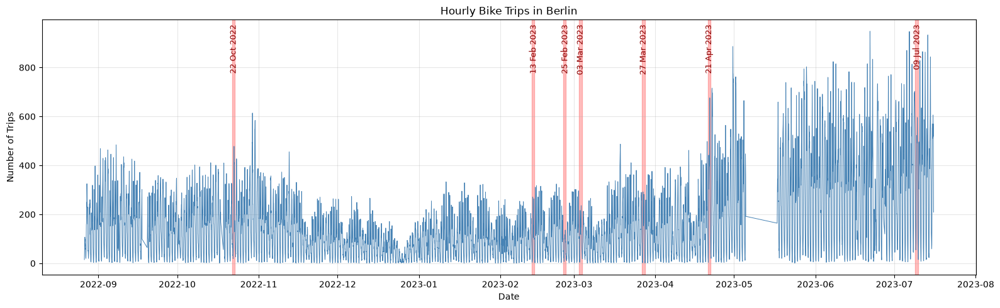

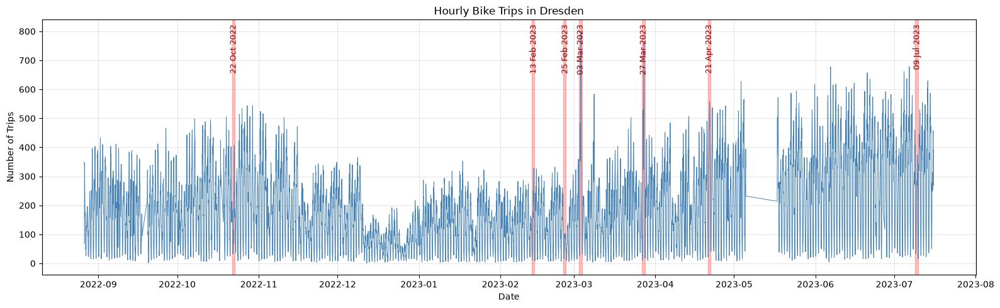

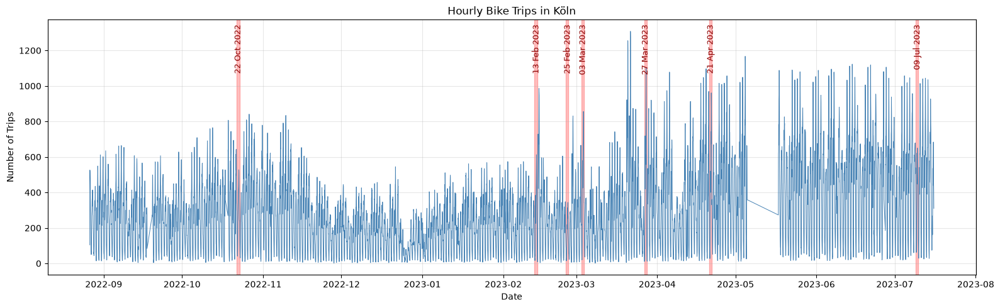

In [269]:
# Dates to highlight
highlight_dates = pd.to_datetime([
    "2022-10-22",
    "2023-02-13",
    "2023-02-25",
    "2023-03-03",
    "2023-03-27",
    "2023-04-21",
    "2023-07-09"
]).tz_localize("Europe/Berlin")


# Create a separate plot for each city
for city in ["Berlin", "Dresden", "Köln"]:

    city_small_df_final = small_df_final[small_df_final["city_name"] == city].sort_values(
        "time_start_berlin_tz"
    )

    fig, ax = plt.subplots(figsize=(16, 5))

    # Plot hourly bike trips
    ax.plot(
        city_small_df_final["time_start_berlin_tz"],
        city_small_df_final["total_bike_usage"],
        linewidth=0.7,
        color="steelblue"
    )

    # Highlight selected dates
    for date in highlight_dates:
        ax.axvspan(
            date,
            date + pd.DateOffset(days=1),
            color="red",
            alpha=0.25
        )


    # Add date label
        ax.text(
            date + pd.Timedelta(hours=12),
            0.98,
            date.strftime("%d %b %Y"),
            rotation=90,
            ha="center",
            va="top",
            fontsize=9,
            color="darkred",
            transform=ax.get_xaxis_transform()
        )    

    ax.set_title(f"Hourly Bike Trips in {city}")
    ax.set_xlabel("Date")
    ax.set_ylabel("Number of Trips")
    ax.grid(alpha=0.3)

    plt.tight_layout()

plt.show()

**Berlin** shows an increased bike demand during the transport strike on April 21, possibly a bit by two demos in Oct 22. No increased demand during the demo on Feb 25 (for negotiations with Russia).               

**Dresden** shows increased bike demand during the transport strikes: March 3 and 27, April 21. No increased demand during the demo (memorial) on Feb 13.        

**Cologne** shows increased bike demand during the transport strike on March 27, somewhat less on March 3, not at all on April 21. No increased demand during the demo (pride) on July 9.

**Overall**, strikes seem to somewhat coincide with an increased bike demand in general, more so for smaller cities: Dresden shows this pattern the most, and it is the smallest city (500.000 in Dresden against 1 mln in Cologne and 3 mln in Berlin). Demos do not seem to matter as much, only the most massive ones: the two protests on Oct 22 in Berlin could have been between 82000 and 100000 people.

For our current analysis, we **did not include strikes** as a predictor because there were only 3 significant strikes over 300+ days of observations. In addition, we could not be 100% sure that on the other dates there were no local strikes affecting public transport or roads. 

For a future, more detailed analysis it would be advisable to include information about any local events that might affect public transport and roads: strikes, large demonstrations, road closures, massive train cancellations, construction sites.